# Step 8 - Retention Framework
**Objective 6:** turn the churn probability (Step 4), the reasons (Step 5), the customer value (Step 6) and the recommended products (Step 7) into a **concrete action for every customer**: who to contact, how, with what offer, and in what priority.

**Input (all from the earlier steps):** `data/churn_predictions_test.csv`, `data/customer_value_test.csv`, `data/shap_top_drivers_test.csv`, `data/recommendations_test_snapshot.csv`, `data/product_lookup.csv`, `data/clean_sales.csv`. Click **Run All** (about 20 seconds).

**Output:** `data/retention_actions_test.csv` (the action list), `data/retention_rules.csv` (the rule table), `data/retention_action_summary.csv`, `models/retention_framework.json` (settings for Steps 9 and 10), `retention_summary.txt` and charts `figures/ret_*.png`.

### What the framework does
For each customer it combines **three inputs**: the churn probability, the customer lifetime value (CLV), and the customer's preferred products (the products they usually buy plus the new products recommended in Step 7). A short, ordered **rule table** (section 4) turns them into one of seven actions, from a personal call down to "no action".

| Action | Who | Cost |
|---|---|---|
| Personal outreach + tailored offer | The few customers where the most money is at risk (limited by account-manager capacity) | highest |
| Win-back email with discount | High churn risk, valuable enough to justify a discount | low + discount |
| Reorder reminder (no discount) | High or medium churn risk, too small for a discount | very low |
| Proactive check-in | Medium risk with some value, or valuable customers with elevated risk | low |
| Loyalty reward + new products | Valuable customers with low risk | medium |
| Cross-sell email | Low risk, medium value | very low |
| No action (monitor) | Low risk, low value | none |

### Important: the numbers for costs and capacity are placeholders
The project data contains **no costs, margins or campaign capacity**. All such figures are **assumptions set in section 1** (marked `ASSUMPTION`) so they can be replaced by real figures with one edit and a re-run. Step 9 tests how sensitive the results are to such assumptions.

### Why "value at risk" and not only risk tiers
The Step 4 *Low* risk tier covers churn probabilities up to about 57%, and customers with a high CLV are almost all in it. Rules that look only at risk tiers would therefore ignore most of the money that is actually exposed. The framework uses the risk tiers for the standard actions and a **value-at-risk ranking (churn probability x CLV)** to decide who gets the scarce personal attention. The notebook shows this with outcomes in section 6.

## 1. Settings and assumptions

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 200
pd.options.display.max_colwidth = 110
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA, FIG, MODELS = Path("data"), Path("figures"), Path("models")
for d in (FIG, MODELS):
    d.mkdir(exist_ok=True)

CUTOFF = pd.Timestamp("2011-07-01")                     # churn test snapshot
CANCELLED_IN_FULL = [541431, 556444, 581483]            # orders removed in Step 2

# =============================================================================================
#  RULE SETTINGS  (the logic of the framework; change and re-run to see the effect)
# =============================================================================================
P_ELEVATED = 0.35            # churn probability from which a customer counts as "elevated risk" (the threshold chosen in Step 4)
N_PERSONAL = 50              # ASSUMPTION: customers the account managers can contact personally in this campaign
MIN_CLV_FOR_DISCOUNT = 150   # ASSUMPTION: a high-risk customer needs at least this expected 12-month revenue (GBP) to be offered a discount

# =============================================================================================
#  ACTION CATALOGUE   (costs in GBP are ASSUMPTIONS, replace them with real figures)
# =============================================================================================
ACTIONS = pd.DataFrame([
    # code,               action,                                   channel,                          cost per contact, discount on next order
    ("PERSONAL",         "Personal outreach + tailored offer",      "Account manager call",             40.00, 0.10),
    ("WINBACK_DISCOUNT", "Win-back email with discount",            "Email + discount code",             0.50, 0.10),
    ("REMINDER",         "Reorder reminder (no discount)",          "Email",                             0.20, 0.00),
    ("CHECKIN",          "Proactive check-in + new products",       "Account manager email",             1.00, 0.00),
    ("LOYALTY",          "Loyalty reward + new products",           "Reward + email",                    5.00, 0.00),
    ("CROSSSELL",        "Cross-sell email",                        "Email",                             0.20, 0.00),
    ("MONITOR",          "No action (monitor)",                     "-",                                 0.00, 0.00),
], columns=["ActionCode", "Action", "Channel", "ContactCostGBP", "DiscountPct"]).set_index("ActionCode")
display(ACTIONS)

,Action,Channel,ContactCostGBP,DiscountPct
ActionCode,,,,
PERSONAL,Personal outreach + tailored offer,Account manager call,40.000,0.100
WINBACK_DISCOUNT,Win-back email with discount,Email + discount code,0.500,0.100
REMINDER,Reorder reminder (no discount),Email,0.200,0.000
CHECKIN,Proactive check-in + new products,Account manager email,1.000,0.000
LOYALTY,Loyalty reward + new products,Reward + email,5.000,0.000
CROSSSELL,Cross-sell email,Email,0.200,0.000
MONITOR,No action (monitor),-,0.000,0.000


## 2. Load and combine the inputs

One row per customer from the 1 July 2011 test snapshot, with the churn probability and risk tier (Step 4), the main reasons for the risk (Step 5), the segment and CLV (Step 6) and the recommended products (Step 7). Every file must cover exactly the same customers.

In [2]:
pred = pd.read_csv(DATA / "churn_predictions_test.csv")
val = pd.read_csv(DATA / "customer_value_test.csv")
why = pd.read_csv(DATA / "shap_top_drivers_test.csv")
recs = pd.read_csv(DATA / "recommendations_test_snapshot.csv", dtype={"StockCode": str})
lookup = pd.read_csv(DATA / "product_lookup.csv", dtype={"StockCode": str})
name_of = dict(zip(lookup["StockCode"], lookup["Description"]))

ids = set(pred["CustomerID"])
assert ids == set(val["CustomerID"]) == set(why["CustomerID"]) == set(recs["CustomerID"]), "the input files cover different customers"

df = (pred[["CustomerID", "Country", "ChurnProbability", "RiskTier", "Churn", "Outcome_FutureSpend"]]
      .merge(val[["CustomerID", "Recency", "Frequency", "Monetary", "SegmentID", "Segment", "ExpPurchases150", "ExpRevenue150",
                  "ExpPurchases12m", "ExpValuePerPurchase", "CLV12m", "ValueTier"]], on="CustomerID", validate="1:1")
      .merge(why[["CustomerID", "RiskDriver1", "RiskDriver2", "RiskDriver3", "WhyAtRisk"]], on="CustomerID", validate="1:1"))
df = df.fillna({"RiskDriver1": "", "RiskDriver2": "", "RiskDriver3": "", "WhyAtRisk": ""})
print(f"{len(df):,} customers from the {CUTOFF:%d %b %Y} snapshot; all four input files cover the same customers  ✓")
display(df[["ChurnProbability", "CLV12m", "ExpRevenue150"]].describe().loc[["mean", "min", "25%", "50%", "75%", "max"]])

4,313 customers from the 01 Jul 2011 snapshot; all four input files cover the same customers  ✓


,ChurnProbability,CLV12m,ExpRevenue150
mean,0.505,"1,514.381",687.710
min,0.022,0.002,0.001
25%,0.340,326.091,148.014
50%,0.574,612.125,278.265
75%,0.692,"1,301.324",590.260
max,0.874,"209,188.816","94,717.137"


## 3. Risk tiers, value tiers and value at risk

* **Risk tier** and **value tier** reuse the definitions of Steps 4 and 6. The notebook reads the probability and CLV cut-off points behind those tiers from the files, so the same cut-off points can be applied to new customers later (a tier then depends on the cut-off, not on the customer's rank in a particular snapshot). The check confirms they reproduce the saved tiers exactly.
* **Value at risk = churn probability x 12-month CLV.** It is a **priority index in GBP**, not a forecast: it says how much expected revenue is exposed to the predicted churn.

In [3]:
cut_med = pred.loc[pred["RiskTier"] == "Medium", "ChurnProbability"].min()
cut_high = pred.loc[pred["RiskTier"] == "High", "ChurnProbability"].min()
clv_med = df.loc[df["ValueTier"] == "Medium", "CLV12m"].min()
clv_high = df.loc[df["ValueTier"] == "High", "CLV12m"].min()


def risk_tier(p):
    return np.select([p >= cut_high, p >= cut_med], ["High", "Medium"], default="Low")


def value_tier(clv):
    return np.select([clv >= clv_high, clv >= clv_med], ["High", "Medium"], default="Low")


assert (risk_tier(df["ChurnProbability"]) == df["RiskTier"]).all(), "risk tier cut-off points do not reproduce Step 4"
assert (value_tier(df["CLV12m"]) == df["ValueTier"]).all(), "value tier cut-off points do not reproduce Step 6"
print(f"Risk tiers : Medium from churn probability {cut_med:.3f}, High from {cut_high:.3f}   (reproduce Step 4 exactly  ✓)")
print(f"Value tiers: Medium from CLV {clv_med:,.0f}, High from {clv_high:,.0f}   (reproduce Step 6 exactly  ✓)")

df["ValueAtRisk"] = df["ChurnProbability"] * df["CLV12m"]
tab = pd.crosstab(df["RiskTier"], df["ValueTier"]).reindex(index=["High", "Medium", "Low"], columns=["High", "Medium", "Low"])
var_share = df.groupby("RiskTier")["ValueAtRisk"].sum() / df["ValueAtRisk"].sum()
print("\nCustomers by risk tier (rows) and value tier (columns):")
display(tab.rename_axis(index="Risk tier", columns="Value tier"))
print("Share of the total value at risk in each risk tier: " + ", ".join(f"{k} {v:.0%}" for k, v in var_share.reindex(["High", "Medium", "Low"]).items()))
print(f"-> only {tab.loc['High', 'High']} customers are both High risk and High value, and {var_share['Low']:.0%} of the value at risk sits in the Low risk tier.")

Risk tiers : Medium from churn probability 0.574, High from 0.712   (reproduce Step 4 exactly  ✓)
Value tiers: Medium from CLV 612, High from 1,601   (reproduce Step 6 exactly  ✓)

Customers by risk tier (rows) and value tier (columns):


Value tier,High,Medium,Low
Risk tier,,,
High,4,28,831
Medium,11,257,1025
Low,847,1009,301


Share of the total value at risk in each risk tier: High 13%, Medium 27%, Low 61%
-> only 4 customers are both High risk and High value, and 61% of the value at risk sits in the Low risk tier.


## 4. The rule table

The rules are checked **in this order; the first rule that matches decides the action.** Each customer gets exactly one action.

| # | Condition | Action | Why |
|---|---|---|---|
| 1 | churn probability >= `P_ELEVATED` **and** among the `N_PERSONAL` highest *value-at-risk* customers of that group | **PERSONAL** | Scarce personal time goes where the most money is exposed |
| 2 | High risk tier **and** CLV >= `MIN_CLV_FOR_DISCOUNT` | **WINBACK_DISCOUNT** | Very likely to leave and worth a discount |
| 3 | High risk tier (CLV below the minimum) | **REMINDER** | Too small for a discount; a cheap reminder with their usual products |
| 4 | Medium risk tier and Medium/High value, **or** probability >= `P_ELEVATED` and High value | **CHECKIN** | Valuable customers with some risk deserve a proactive contact before they become high risk |
| 5 | Medium risk tier (Low value) | **REMINDER** | Cheap nudge |
| 6 | High value (and low risk) | **LOYALTY** | Protect and grow the best customers |
| 7 | Medium value (and low risk) | **CROSSSELL** | Grow spend with recommended products |
| 8 | everything else | **MONITOR** | Low risk, low value: no spend |

**Offer content** (what the message or call contains) comes from the customer's own data:
* the **usual products**: the 3 products in the most orders before the cut-off;
* the **recommended new products**: the top 3 from the Step 7 recommender;
* the **angle**: the main behavioural reason for the risk from Step 5 (SHAP): *timing* (longer than usual since the last order), *frequency* (ordering less often than loyal customers), *spend* (an order-size or spend pattern like that of customers who leave) or *service* (a high return rate, which should be fixed before any discount is offered). Customers with only **one order** get the *one-time* angle (aim: a second order), because they have no usual rhythm yet. `Tenure` and `Country` are not used for the angle because they do not describe something the company can address in a message.

In [4]:
# ---- preferred products: usual products and recommended new products ------------------------
sales = pd.read_csv(DATA / "clean_sales.csv", parse_dates=["InvoiceDate"], dtype={"StockCode": str},
                    usecols=["Invoice", "StockCode", "Quantity", "InvoiceDate", "CustomerID"])
sales = sales[(sales["InvoiceDate"] < CUTOFF) & ~sales["Invoice"].isin(CANCELLED_IN_FULL) & sales["CustomerID"].isin(ids)]
fav = (sales.groupby(["CustomerID", "StockCode"]).agg(Orders=("Invoice", "nunique"), Units=("Quantity", "sum")).reset_index()
       .sort_values(["CustomerID", "Orders", "Units"], ascending=[True, False, False]).groupby("CustomerID").head(3))
fav["Name"] = fav["StockCode"].map(name_of).fillna(fav["StockCode"]).str.title()
rec3 = recs[recs["Rank"] <= 3].copy()
rec3["Name"] = rec3["Description"].fillna(rec3["StockCode"]).str.title()

df["FavouriteProducts"] = df["CustomerID"].map(fav.groupby("CustomerID")["Name"].apply(" | ".join))
df["RecommendedProducts"] = df["CustomerID"].map(rec3.sort_values(["CustomerID", "Rank"]).groupby("CustomerID")["Name"].apply(" | ".join))
assert df["FavouriteProducts"].notna().all() and df["RecommendedProducts"].notna().all()
print("Example:", df.iloc[0]["CustomerID"], "| usual:", df.iloc[0]["FavouriteProducts"], "| recommended:", df.iloc[0]["RecommendedProducts"])

# ---- message angle from the main behavioural risk driver (Step 5) -----------------------------
DRIVER_ANGLE = {"Recency": "timing", "RecencyGapRatio": "timing", "AvgGapDays": "timing", "StdGapDays": "timing",
                "Frequency": "frequency", "PurchaseRate": "frequency", "Orders90": "frequency", "OrdersTrend": "frequency",
                "Monetary": "spend", "Spend90": "spend", "SpendTrend": "spend", "AvgOrderValue": "spend", "AvgItemsPerOrder": "spend",
                "AvgLinesPerOrder": "spend", "DistinctProducts": "spend", "ReturnRate": "service", "ReturnCount": "service"}
ANGLE_TEXT = {"timing": "it has been longer than usual since the last order",
              "frequency": "orders are less frequent than for loyal customers",
              "spend": "the spend and order-size pattern resembles customers who leave",
              "service": "returns are unusually high",
              "onetime": "the customer has placed only one order so far, so the aim is a second order",
              "general": "the overall buying pattern points to a risk of leaving"}


def angle_of(row):
    if row["Frequency"] == 1:                    # a single order: there is no "usual rhythm" to talk about
        return "onetime"
    for c in ("RiskDriver1", "RiskDriver2", "RiskDriver3"):
        if row[c] in DRIVER_ANGLE:
            return DRIVER_ANGLE[row[c]]
    return "general"


df["MessageAngle"] = df.apply(angle_of, axis=1)
print("\nMessage angle across all customers:", df["MessageAngle"].value_counts().to_dict())

Example: 12347 | usual: Small Heart Measuring Spoons | 3D Dog Picture Playing Cards | Airline Bag Vintage Jet Set Brown | recommended: Pack Of 60 Pink Paisley Cake Cases | Alarm Clock Bakelike Ivory | Green 3 Piece Mini Dots Cutlery Set

Message angle across all customers: {'timing': 1256, 'onetime': 1051, 'frequency': 865, 'spend': 549, 'general': 459, 'service': 133}


In [5]:
RULES = pd.DataFrame([
    (1, "PERSONAL", "churn probability >= P_ELEVATED and within the N_PERSONAL highest value-at-risk customers", "most money at risk gets the scarce personal time"),
    (2, "WINBACK_DISCOUNT", "High risk tier and CLV >= MIN_CLV_FOR_DISCOUNT", "very likely to leave and valuable enough for a discount"),
    (3, "REMINDER", "High risk tier (CLV below the discount minimum)", "too small for a discount: cheap reminder"),
    (4, "CHECKIN", "Medium risk tier with Medium/High value, or churn probability >= P_ELEVATED with High value", "valuable customers with some risk: proactive contact"),
    (5, "REMINDER", "Medium risk tier (Low value)", "cheap nudge"),
    (6, "LOYALTY", "High value (and low risk)", "protect and grow the best customers"),
    (7, "CROSSSELL", "Medium value (and low risk)", "grow spend with recommendations"),
    (8, "MONITOR", "everything else (low risk, low value)", "no spend"),
], columns=["Order", "ActionCode", "Condition", "Why"])


def assign_actions(d, p_elevated=P_ELEVATED, n_personal=N_PERSONAL, min_clv_discount=MIN_CLV_FOR_DISCOUNT):
    """Apply the rule table. d needs ChurnProbability, CLV12m (risk and value tiers are derived from the fixed cut-off points)."""
    d = d.copy()
    d["RiskTier"] = risk_tier(d["ChurnProbability"])
    d["ValueTier"] = value_tier(d["CLV12m"])
    d["ValueAtRisk"] = d["ChurnProbability"] * d["CLV12m"]
    elevated = d["ChurnProbability"] >= p_elevated
    var_rank = d["ValueAtRisk"].where(elevated).rank(ascending=False, method="first")
    r_high, r_med = d["RiskTier"] == "High", d["RiskTier"] == "Medium"
    v_high, v_med, v_low = d["ValueTier"] == "High", d["ValueTier"] == "Medium", d["ValueTier"] == "Low"
    conditions = [elevated & (var_rank <= n_personal),
                  r_high & (d["CLV12m"] >= min_clv_discount),
                  r_high,
                  (r_med & ~v_low) | (elevated & v_high),
                  r_med,
                  v_high,
                  v_med]
    codes = ["PERSONAL", "WINBACK_DISCOUNT", "REMINDER", "CHECKIN", "REMINDER", "LOYALTY", "CROSSSELL"]
    d["ActionCode"] = np.select(conditions, codes, default="MONITOR")
    d["RuleFired"] = np.select(conditions, [1, 2, 3, 4, 5, 6, 7], default=8)
    d["Priority"] = d["ValueAtRisk"].where(d["ActionCode"] != "MONITOR").rank(ascending=False, method="first")   # 1 = work on first
    return d


def offer_text(r):
    fav, rec = r["FavouriteProducts"].split(" | "), r["RecommendedProducts"].split(" | ")
    disc = ACTIONS.loc[r["ActionCode"], "DiscountPct"]
    service = " Resolve the returns / quality issue first." if r["MessageAngle"] == "service" else ""
    a = r["ActionCode"]
    if a == "PERSONAL":
        lead = ("Account manager call, starting with service recovery (returns are unusually high)" if r["MessageAngle"] == "service"
                else f"Account manager call: {ANGLE_TEXT[r['MessageAngle']]}")
        return (f"{lead}. Then suggest restocking {', '.join(fav)}; introduce {', '.join(rec[:2])}; "
                f"offer a tailored {disc:.0%} discount on the next order.")
    if a == "WINBACK_DISCOUNT":
        return f"Email with a {disc:.0%} discount code on the next order, featuring the usual products: {', '.join(fav)}.{service}"
    if a == "REMINDER":
        return f"Reorder reminder email featuring the usual products: {', '.join(fav)}.{service}"
    if a == "CHECKIN":
        return f"Check-in email from the account manager: new products picked for them ({', '.join(rec)}); usual products {', '.join(fav[:2])}.{service}"
    if a == "LOYALTY":
        return f"Thank-you reward (priority service or credit) and early access to new products: {', '.join(rec)}."
    if a == "CROSSSELL":
        return f"Email: new products picked for this customer: {', '.join(rec)}."
    return "No contact; keep monitoring."

## 5. Apply the rules to the test customers

In [6]:
act = assign_actions(df)
act = act.join(ACTIONS, on="ActionCode")
act["Offer"] = act.apply(offer_text, axis=1)
act["MaxDiscountCostGBP"] = act["DiscountPct"] * act["ExpValuePerPurchase"]       # cost of the discount if the customer redeems it on one typical order

assert len(act) == len(df) and act["ActionCode"].notna().all()
assert (act["ActionCode"] == "PERSONAL").sum() == N_PERSONAL
assert (act["RiskTier"] == df["RiskTier"]).all()

summary = act.groupby("ActionCode").agg(
    Customers=("CustomerID", "size"), AvgChurnProb=("ChurnProbability", "mean"), AvgCLV=("CLV12m", "mean"),
    TotalCLV=("CLV12m", "sum"), TotalValueAtRisk=("ValueAtRisk", "sum"), ContactCost=("ContactCostGBP", "sum"),
    MaxDiscountCost=("MaxDiscountCostGBP", "sum"),
    ActualChurnRate=("Churn", "mean")).reindex(ACTIONS.index)
summary.insert(1, "ShareOfCustomers", summary["Customers"] / len(act))
summary["ShareOfValueAtRisk"] = summary["TotalValueAtRisk"] / summary["TotalValueAtRisk"].sum()
summary.insert(0, "Action", ACTIONS["Action"])
display(summary)
contacted = act["ActionCode"] != "MONITOR"
print(f"\n{contacted.sum():,} of {len(act):,} customers get a contact ({contacted.mean():.0%}); they hold {act.loc[contacted, 'ValueAtRisk'].sum() / act['ValueAtRisk'].sum():.0%} of the value at risk.")
print(f"Contact cost of the whole campaign: GBP {act['ContactCostGBP'].sum():,.0f} (assumed unit costs); discount cost if every discounted customer redeemed one typical order: GBP {act['MaxDiscountCostGBP'].sum():,.0f}.")
print("(Actual churn rate is shown only to check that the groups really differ; it is not used by the rules.)")

,Action,Customers,ShareOfCustomers,AvgChurnProb,AvgCLV,TotalCLV,TotalValueAtRisk,ContactCost,MaxDiscountCost,ActualChurnRate,ShareOfValueAtRisk
ActionCode,,,,,,,,,,,
PERSONAL,Personal outreach + tailored offer,50,0.012,0.550,"3,355.248","167,762.421","86,683.412","2,000.000","8,197.944",0.360,0.058
WINBACK_DISCOUNT,Win-back email with discount,781,0.181,0.757,281.869,"220,139.881","165,759.190",390.500,"26,159.907",0.703,0.110
REMINDER,Reorder reminder (no discount),1099,0.255,0.665,362.575,"398,469.709","260,986.064",219.800,0.000,0.678,0.174
CHECKIN,Proactive check-in + new products,302,0.070,0.592,971.016,"293,246.874","164,168.985",302.000,0.000,0.507,0.109
LOYALTY,Loyalty reward + new products,771,0.179,0.132,"5,550.288","4,279,271.979","361,619.600","3,855.000",0.000,0.078,0.241
CROSSSELL,Cross-sell email,1009,0.234,0.395,"1,020.600","1,029,785.038","391,262.062",201.800,0.000,0.290,0.261
MONITOR,No action (monitor),301,0.070,0.495,474.580,"142,848.460","70,105.800",0.000,0.000,0.502,0.047



4,012 of 4,313 customers get a contact (93%); they hold 95% of the value at risk.
Contact cost of the whole campaign: GBP 6,969 (assumed unit costs); discount cost if every discounted customer redeemed one typical order: GBP 34,358.
(Actual churn rate is shown only to check that the groups really differ; it is not used by the rules.)


## 6. Why value at risk? A check with what really happened

The personal-outreach slots are scarce, so how they are allocated matters. Three ways of picking the `N` customers to call are compared, using **what customers actually did afterwards**:

* **by churn probability only** (the highest probabilities),
* **by CLV only** (the most valuable customers),
* **by value at risk** among customers with an elevated churn probability (the rule used here).

The measure is the revenue that **actual churners were expected to bring but did not** (their predicted 150-day revenue from Step 6, counted only for customers who really churned). It is a validation measure from outcomes; it is *not* used to build the rules. The random line is the average of picking customers at random.

In [7]:
act["RealisedExposure"] = np.where(act["Churn"] == 1, act["ExpRevenue150"], 0.0)
total_exp = act["RealisedExposure"].sum()
elev = act[act["ChurnProbability"] >= P_ELEVATED]
Ns = [25, 50, 100, 200, 400, 800]
rows = []
for n in Ns:
    rows.append({"N": n,
                 "By churn probability": act.nlargest(n, "ChurnProbability")["RealisedExposure"].sum() / total_exp,
                 "By CLV": act.nlargest(n, "CLV12m")["RealisedExposure"].sum() / total_exp,
                 "By value at risk": elev.nlargest(n, "ValueAtRisk")["RealisedExposure"].sum() / total_exp,
                 "Random": n / len(act)})
cmp_ = pd.DataFrame(rows).set_index("N")
print(f"Share of the expected-but-lost revenue of actual churners (total {total_exp:,.0f}) captured by the N customers chosen:")
display((cmp_ * 100).round(1).add_suffix(" (%)"))

n0 = N_PERSONAL if N_PERSONAL in Ns else 50
best_other = max(cmp_.loc[n0, "By churn probability"], cmp_.loc[n0, "By CLV"])
print(f"\nFor N = {n0}: value at risk captures {cmp_.loc[n0, 'By value at risk'] * 100:.1f}% against {cmp_.loc[n0, 'By churn probability'] * 100:.1f}% by probability, "
      f"{cmp_.loc[n0, 'By CLV'] * 100:.1f}% by CLV and {cmp_.loc[n0, 'Random'] * 100:.1f}% at random.")
print(f"-> {cmp_.loc[n0, 'By value at risk'] / best_other:.1f}x the best of the two single-criterion rules." if best_other > 0 else "")
print("Caution: this is one snapshot; a handful of very large customers drive these shares, and the lost-revenue measure itself uses the Step 6 value model, "
      "so it favours rules that look at value (see the limits at the end).")

Share of the expected-but-lost revenue of actual churners (total 515,676) captured by the N customers chosen:


,By churn probability (%),By CLV (%),By value at risk (%),Random (%)
N,,,,
25,0.300,2.700,6.000,0.600
50,0.600,2.700,7.300,1.200
100,1.500,4.300,9.900,2.300
200,3.200,7.000,14.300,4.600
400,6.400,11.700,20.700,9.300
800,13.200,21.900,33.300,18.500



For N = 50: value at risk captures 7.3% against 0.6% by probability, 2.7% by CLV and 1.2% at random.
-> 2.7x the best of the two single-criterion rules.
Caution: this is one snapshot; a handful of very large customers drive these shares, and the lost-revenue measure itself uses the Step 6 value model, so it favours rules that look at value (see the limits at the end).


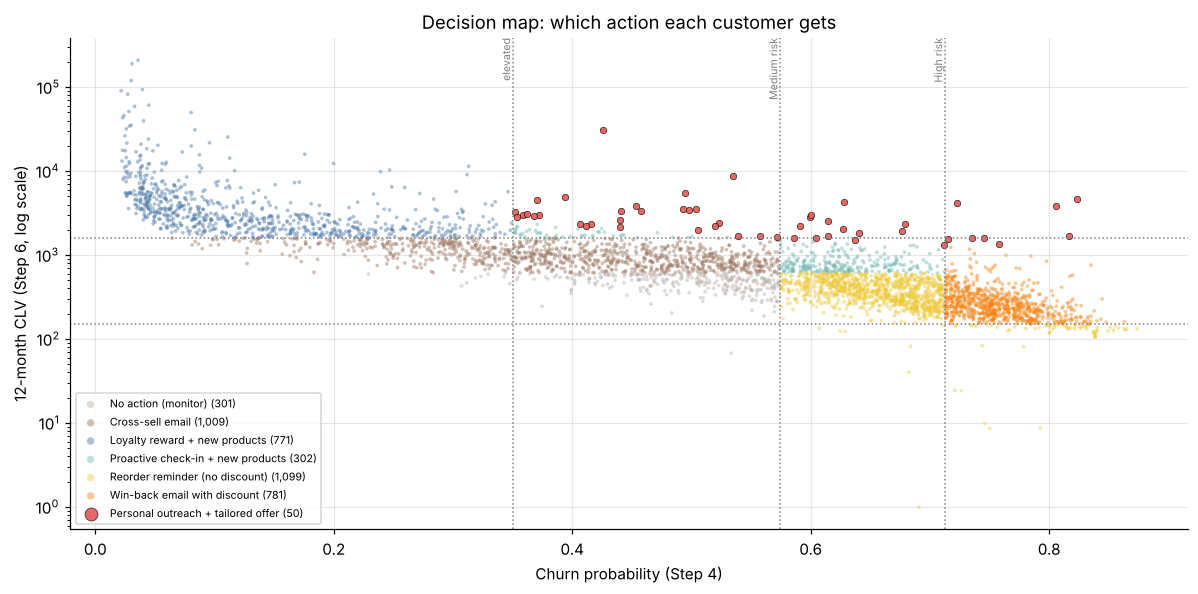

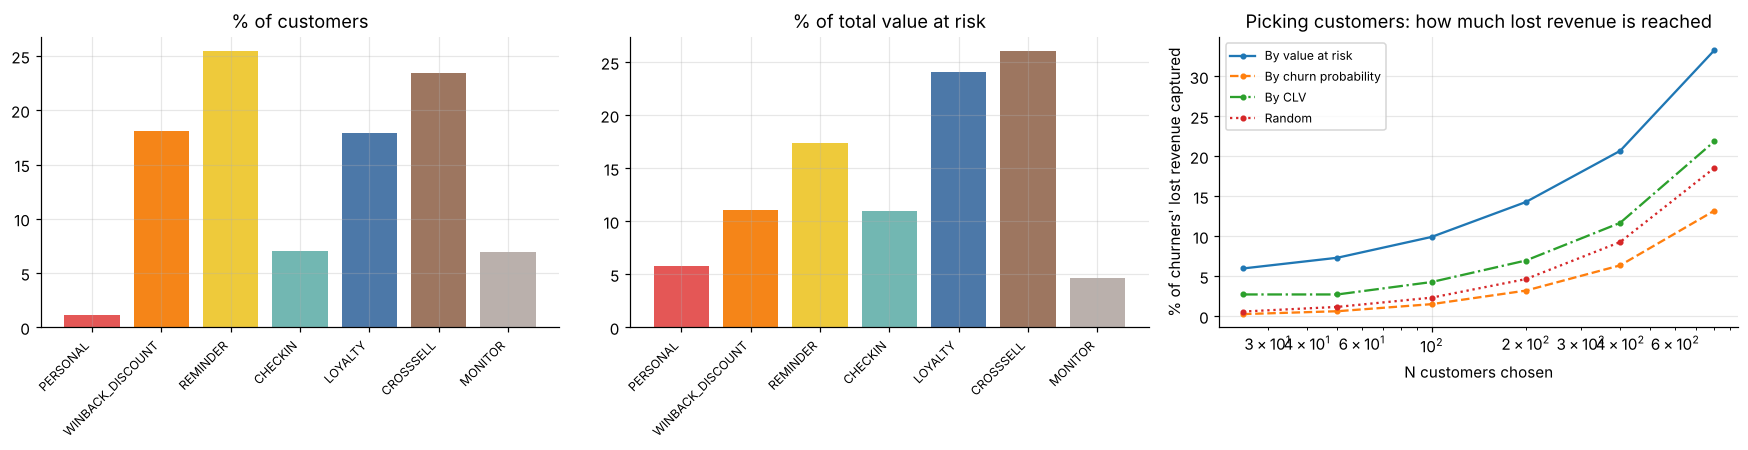

In [8]:
colors = {"PERSONAL": "#E45756", "WINBACK_DISCOUNT": "#F58518", "REMINDER": "#EECA3B", "CHECKIN": "#72B7B2",
          "LOYALTY": "#4C78A8", "CROSSSELL": "#9D7660", "MONITOR": "#BAB0AC"}

# ---- decision map
fig, ax = plt.subplots(figsize=(11, 5.5))
for code_ in ACTIONS.index[::-1]:
    m = act["ActionCode"] == code_
    ax.scatter(act.loc[m, "ChurnProbability"], act.loc[m, "CLV12m"].clip(lower=1), s=18 if code_ == "PERSONAL" else 6,
               alpha=0.9 if code_ == "PERSONAL" else 0.45, color=colors[code_], label=f"{ACTIONS.loc[code_, 'Action']} ({m.sum():,})",
               edgecolor="k" if code_ == "PERSONAL" else "none", linewidth=0.4)
ax.set_yscale("log"); ax.set_xlabel("Churn probability (Step 4)"); ax.set_ylabel("12-month CLV (Step 6, log scale)")
for x_, lab in [(cut_med, "Medium risk"), (cut_high, "High risk"), (P_ELEVATED, "elevated")]:
    ax.axvline(x_, color="grey", ls=":", lw=1); ax.text(x_, ax.get_ylim()[1], lab, rotation=90, va="top", ha="right", fontsize=7, color="grey")
ax.axhline(clv_high, color="grey", ls=":", lw=1); ax.axhline(MIN_CLV_FOR_DISCOUNT, color="grey", ls=":", lw=1)
ax.set_title("Decision map: which action each customer gets"); ax.legend(fontsize=7, loc="lower left", markerscale=2)
plt.tight_layout(); plt.savefig(FIG / "ret_decision_map.png", dpi=120); plt.show()

# ---- action mix and targeting comparison
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
idx = np.arange(len(ACTIONS))
ax[0].bar(idx, summary["ShareOfCustomers"] * 100, color=[colors[c] for c in ACTIONS.index]); ax[0].set_title("% of customers")
ax[1].bar(idx, summary["ShareOfValueAtRisk"] * 100, color=[colors[c] for c in ACTIONS.index]); ax[1].set_title("% of total value at risk")
for a in ax[:2]:
    a.set_xticks(idx); a.set_xticklabels(ACTIONS.index, rotation=45, ha="right", fontsize=8)
for col, st in [("By value at risk", "-"), ("By churn probability", "--"), ("By CLV", "-."), ("Random", ":")]:
    ax[2].plot(cmp_.index, cmp_[col] * 100, st, marker="o", ms=3, label=col)
ax[2].set_xscale("log"); ax[2].set_xlabel("N customers chosen"); ax[2].set_ylabel("% of churners' lost revenue captured")
ax[2].set_title("Picking customers: how much lost revenue is reached"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "ret_action_mix.png", dpi=120); plt.show()

## 7. What the action list looks like

One example per action (the customer with the highest value at risk in each group). The `Offer` column is the text a campaign team would use.

In [9]:
show = []
for c in ACTIONS.index:
    g = act[act["ActionCode"] == c].sort_values("ValueAtRisk", ascending=False)
    if len(g):
        show.append(g.iloc[0])
ex = pd.DataFrame(show)[["CustomerID", "Segment", "ChurnProbability", "RiskTier", "CLV12m", "ValueTier", "ValueAtRisk", "ActionCode", "MessageAngle", "WhyAtRisk", "Offer"]]
display(ex.reset_index(drop=True))
print("\nFirst 3 personal-outreach customers:")
for _, r in act[act["ActionCode"] == "PERSONAL"].nsmallest(3, "Priority").iterrows():
    print(f"\n#{int(r['Priority'])} customer {r['CustomerID']} ({r['Segment']}): churn probability {r['ChurnProbability']:.0%}, CLV {r['CLV12m']:,.0f}, value at risk {r['ValueAtRisk']:,.0f}")
    print(f"   why: {r['WhyAtRisk'] or 'no single dominant driver'}")
    print(f"   {r['Offer']}")

,CustomerID,Segment,ChurnProbability,RiskTier,CLV12m,ValueTier,ValueAtRisk,ActionCode,MessageAngle,WhyAtRisk,Offer
0,15749,At-risk regulars,0.426,Low,"30,663.413",High,"13,064.313",PERSONAL,service,"ReturnRate = 0.52 (+5 pp); AvgItemsPerOrder = 6,009 (+3 pp); DistinctProducts = 5 (+3 pp)","Account manager call, starting with service recovery (returns are unusually high). Then suggest restocking..."
1,16772,At-risk regulars,0.717,High,"1,230.673",Medium,882.953,WINBACK_DISCOUNT,timing,Recency = 262 (+9 pp); Tenure = 560 (+7 pp); PurchaseRate = 0.16 (+7 pp),"Email with a 10% discount code on the next order, featuring the usual products: Red Retrospot Cake Stand, ..."
2,13154,At-risk regulars,0.695,Medium,610.610,Low,424.633,REMINDER,timing,Tenure = 574 (+9 pp); Recency = 238 (+8 pp); PurchaseRate = 0.16 (+6 pp),"Reorder reminder email featuring the usual products: Inflatable Political Globe, White Hanging Heart T-Lig..."
3,16636,At-risk regulars,0.686,Medium,"1,305.796",Medium,896.164,CHECKIN,timing,Recency = 277 (+14 pp); Tenure = 485 (+7 pp); PurchaseRate = 0.25 (+5 pp),"Check-in email from the account manager: new products picked for them (Feltcraft 6 Flower Friends, Strawbe..."
4,18102,Champions,0.036,Low,"209,188.816",High,"7,481.935",LOYALTY,spend,"AvgItemsPerOrder = 1,348 (+3 pp); Tenure = 577 (+2 pp); AvgLinesPerOrder = 6.93 (+1 pp)","Thank-you reward (priority service or credit) and early access to new products: Lunch Bag Suki Design, I'..."
5,14737,At-risk regulars,0.572,Low,"1,494.185",Medium,854.912,CROSSSELL,timing,Recency = 192 (+6 pp); Tenure = 239 (+2 pp); Spend90 = 0 (+2 pp),"Email: new products picked for this customer: Paper Chain Kit Empire, Set Of 20 Vintage Christmas Napkins,..."
6,14246,Lapsed low-frequency customers,0.573,Low,593.724,Low,340.254,MONITOR,onetime,AvgGapDays = no history (+4 pp); Frequency = 1 (+2 pp); Recency = 84 (+2 pp),No contact; keep monitoring.



First 3 personal-outreach customers:

#1 customer 15749 (At-risk regulars): churn probability 43%, CLV 30,663, value at risk 13,064
   why: ReturnRate = 0.52 (+5 pp); AvgItemsPerOrder = 6,009 (+3 pp); DistinctProducts = 5 (+3 pp)
   Account manager call, starting with service recovery (returns are unusually high). Then suggest restocking Fairy Cake Flannel Assorted Colour, Gin + Tonic Diet Metal Sign, White Hanging Heart T-Light Holder; introduce Red Hanging Heart T-Light Holder, Candleholder Pink Hanging Heart; offer a tailored 10% discount on the next order.

#4 customer 12590 (At-risk regulars): churn probability 54%, CLV 8,704, value at risk 4,658
   why: AvgItemsPerOrder = 4,282 (+5 pp); AvgGapDays = no history (+5 pp); StdGapDays = no history (+3 pp)
   Account manager call: the customer has placed only one order so far, so the aim is a second order. Then suggest restocking Assorted Colours Silk Fan, Woodland Charlotte Bag, Strawberry Charlotte Bag; introduce Charlotte Bag Pink 

## 8. Save the results

* `retention_actions_test.csv` - the **action list**, one row per customer, ordered by priority (value at risk). Use it for the dashboard's retention list.
* `retention_rules.csv` - the rule table with the settings used.
* `retention_action_summary.csv` - the table of section 5.
* `models/retention_framework.json` - settings, cut-off points, action catalogue and rules, so that Step 9 (simulation) and Step 10 (dashboard) use the same definitions and `assign_actions` can be applied to a new snapshot.

In [10]:
cols = ["CustomerID", "Priority", "ActionCode", "Action", "Channel", "Segment", "ChurnProbability", "RiskTier", "CLV12m", "ValueTier", "ValueAtRisk",
        "MessageAngle", "WhyAtRisk", "FavouriteProducts", "RecommendedProducts", "Offer", "ContactCostGBP", "DiscountPct", "MaxDiscountCostGBP", "RuleFired",
        "Country", "Recency", "Frequency", "Monetary"]
out = act[cols].copy()
out.insert(1, "SnapshotDate", f"{CUTOFF:%Y-%m-%d}")
out = out.sort_values(["Priority", "ValueAtRisk"], ascending=[True, False], na_position="last").reset_index(drop=True)
out.to_csv(DATA / "retention_actions_test.csv", index=False)

rules_out = RULES.assign(Settings=f"P_ELEVATED={P_ELEVATED}; N_PERSONAL={N_PERSONAL}; MIN_CLV_FOR_DISCOUNT={MIN_CLV_FOR_DISCOUNT}; risk cut-offs {cut_med:.3f}/{cut_high:.3f}; CLV cut-offs {clv_med:,.0f}/{clv_high:,.0f}")
rules_out = rules_out.merge(ACTIONS.reset_index(), on="ActionCode", how="left")
rules_out.to_csv(DATA / "retention_rules.csv", index=False)
summary.reset_index().to_csv(DATA / "retention_action_summary.csv", index=False)

framework = {"created_for_cutoff": f"{CUTOFF:%Y-%m-%d}",
             "settings": {"P_ELEVATED": P_ELEVATED, "N_PERSONAL": N_PERSONAL, "MIN_CLV_FOR_DISCOUNT": MIN_CLV_FOR_DISCOUNT},
             "risk_tier_cutoffs": {"medium_from": float(cut_med), "high_from": float(cut_high)},
             "value_tier_cutoffs_clv12m": {"medium_from": float(clv_med), "high_from": float(clv_high)},
             "actions_ASSUMED_costs_gbp": ACTIONS.reset_index().to_dict(orient="records"),
             "rules_in_order": RULES.to_dict(orient="records"),
             "angle_by_driver": DRIVER_ANGLE}
(MODELS / "retention_framework.json").write_text(json.dumps(framework, indent=2), encoding="utf-8")

for f in ("retention_actions_test.csv", "retention_rules.csv", "retention_action_summary.csv"):
    print(f"saved data/{f}  ({(DATA / f).stat().st_size / 1e6:.2f} MB)")
print("saved models/retention_framework.json")

saved data/retention_actions_test.csv  (2.60 MB)
saved data/retention_rules.csv  (0.00 MB)
saved data/retention_action_summary.csv  (0.00 MB)
saved models/retention_framework.json


## 9. Summary of findings

In [11]:
p_row = summary.loc["PERSONAL"]
lines = [
    f"Framework: {len(RULES)} ordered rules over churn probability (Step 4), CLV (Step 6), reasons (Step 5) and preferred products (Steps 1 and 7) give each of the {len(act):,} test customers one of {len(ACTIONS)} actions.",
    "Action mix: " + ", ".join(f"{c} {int(r.Customers):,}" for c, r in summary.iterrows()) + ".",
    f"{contacted.sum():,} customers ({contacted.mean():.0%}) are contacted and hold {act.loc[contacted, 'ValueAtRisk'].sum() / act['ValueAtRisk'].sum():.0%} of the value at risk; assumed contact cost GBP {act['ContactCostGBP'].sum():,.0f}.",
    f"Only {tab.loc['High', 'High']} customers are both High risk and High value, and {var_share['Low']:.0%} of the value at risk lies in the Low risk tier, so personal outreach is allocated by value at risk, not by risk tier.",
    f"Costly actions are limited: personal call {int(summary.loc['PERSONAL', 'Customers'])} customers, discount {int(summary.loc['WINBACK_DISCOUNT', 'Customers']):,}, loyalty reward {int(summary.loc['LOYALTY', 'Customers']):,}; the rest are low-cost emails or no contact.",
    f"Personal outreach: {int(p_row.Customers)} customers (assumed capacity), average churn probability {p_row.AvgChurnProb:.2f}, average CLV {p_row.AvgCLV:,.0f}, holding {p_row.ShareOfValueAtRisk:.0%} of the value at risk.",
    f"Check with outcomes (N = {n0}): the value-at-risk list captures {cmp_.loc[n0, 'By value at risk'] * 100:.1f}% of the revenue that churners were expected to bring, against {cmp_.loc[n0, 'By churn probability'] * 100:.1f}% by probability, {cmp_.loc[n0, 'By CLV'] * 100:.1f}% by CLV and {cmp_.loc[n0, 'Random'] * 100:.1f}% at random.",
    "All costs, the personal-outreach capacity and the discount minimum are placeholder assumptions; the effect of the actions on churn is NOT measured here and is estimated by simulation in Step 9.",
]
print("KEY FINDINGS")
print("=" * 60)
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}")
Path("retention_summary.txt").write_text("\n".join(f"{i}. {l}" for i, l in enumerate(lines, 1)), encoding="utf-8")
print("\nSaved retention_summary.txt")

KEY FINDINGS
1. Framework: 8 ordered rules over churn probability (Step 4), CLV (Step 6), reasons (Step 5) and preferred products (Steps 1 and 7) give each of the 4,313 test customers one of 7 actions.
2. Action mix: PERSONAL 50, WINBACK_DISCOUNT 781, REMINDER 1,099, CHECKIN 302, LOYALTY 771, CROSSSELL 1,009, MONITOR 301.
3. 4,012 customers (93%) are contacted and hold 95% of the value at risk; assumed contact cost GBP 6,969.
4. Only 4 customers are both High risk and High value, and 61% of the value at risk lies in the Low risk tier, so personal outreach is allocated by value at risk, not by risk tier.
5. Costly actions are limited: personal call 50 customers, discount 781, loyalty reward 771; the rest are low-cost emails or no contact.
6. Personal outreach: 50 customers (assumed capacity), average churn probability 0.55, average CLV 3,355, holding 6% of the value at risk.
7. Check with outcomes (N = 50): the value-at-risk list captures 7.3% of the revenue that churners were expected 

## How to use this, and limits to state in the report

**Changing the assumptions.** Edit `N_PERSONAL`, `P_ELEVATED`, `MIN_CLV_FOR_DISCOUNT` and the `ACTIONS` table in section 1 (costs, discounts), then **Run All**. Every output file follows.

**Step 9 (evaluation and simulation).** `retention_actions_test.csv` and `models/retention_framework.json` define who is contacted, with which action, at which cost and discount. Step 9 adds an *assumed* effect of each action on churn (with a sensitivity analysis over a range of values), and compares this targeting with random targeting and with targeting by risk only. Real customer outcomes (`Churn`, `Outcome_FutureSpend`) exist for this snapshot, but they come from customers who were **not** contacted, so the effect of the actions cannot be measured from them.

**Step 10 (dashboard).** The action list gives the "retention action list" page directly: filter by action, segment or risk tier, sorted by `Priority`. The `Offer` and `WhyAtRisk` columns can be shown on the customer-profile page.

**Today's customers.** `assign_actions` works on any table with `ChurnProbability` and `CLV12m`. The value side already exists in `data/customer_value_current.csv` (end of data), but the churn probabilities for that date need the Step 4 model scored on a new snapshot, which was not available here.

**Limits to state**
* **Costs, capacity and discount sizes are assumptions**, not data. The rules are a reasoned structure whose thresholds should be set with the business.
* **Value at risk is a priority index**, not a forecast: it multiplies two model outputs (the Step 4 probability and the Step 6 CLV), and CLV itself already allows for customers leaving.
* **Hard thresholds create cliffs.** A customer just below a cut-off (for example a churn probability of 0.573 against the Medium cut-off 0.574) gets a cheaper action than one just above; the cut-offs are placed with the business, and Step 9 shows how sensitive the results are to them.
* **A few very large customers dominate the money at risk**, so the comparison in section 6 depends on a small number of accounts; it supports the design but is not a precise estimate.
* **The Step 5 reasons describe what the churn model relies on**, not proven causes. `Tenure`, the model's second most important feature, is ignored for the message angle (it is partly an artefact of the dataset's start date, see Step 5).
* **One snapshot (1 July 2011), no campaign history.** Nothing here measures whether an offer works; the effectiveness is estimated by simulation in Step 9.